**2D Grid World Environment with Q-table**

- Rewards
- Traps
- Walls
- Agent
- Goal
- 4 actions and (consider -> 5x5 matrix -> 25 states)

In [1]:
import random
import matplotlib.pyplot as plt
import numpy as np
import gymnasium as gym
from gymnasium import spaces

In [2]:
# 2D Grid World Environment

class GridWorldEnv(gym.Env):
    """A simple 2D GridWorld with walls, a trap, and a goal."""

    def __init__(self, max_steps=100):
        super().__init__()

        self.size = 5
        self.start = (0, 0)
        self.goal = (4, 4)
        self.trap = (1, 3)
        self.max_steps = max_steps

        self.walls = {
            (1, 1),
            (3, 0),
            (3, 2),
        }

        # 0 = Up, 1 = Down, 2 = Left, 3 = Right
        self.action_space = spaces.Discrete(4)

        # Each grid position is represented by an integer 0-24.
        self.observation_space = spaces.Discrete(
            self.size * self.size
        )

        self.position = self.start
        self.elapsed_steps = 0

    def _get_state(self):
        """Convert (row, col) into a single integer."""
        row, col = self.position
        
        # p(state) = r * s + c
        return row * self.size + col

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)

        self.position = self.start
        self.elapsed_steps = 0

        return self._get_state(), {}

    def step(self, action):
        if not self.action_space.contains(action):
            raise ValueError(f"Invalid action: {action}")

        row, col = self.position

        # Calculate the proposed next position.
        if action == 0:
            next_position = (row - 1, col)
        elif action == 1:
            next_position = (row + 1, col)
        elif action == 2:
            next_position = (row, col - 1)
        else:
            next_position = (row, col + 1)

        next_row, next_col = next_position

        # Check boundaries and walls.
        inside_grid = (
            0 <= next_row < self.size
            and 0 <= next_col < self.size
        )

        if inside_grid and next_position not in self.walls:
            self.position = next_position

        # Calculate reward.
        reward = -1
        terminated = False

        if self.position == self.goal:
            reward = 10
            terminated = True
        elif self.position == self.trap:
            reward = -10
            terminated = True

        observation = self._get_state()
        truncated = False
        info = {"position": self.position}

        return (
            observation,
            reward,
            terminated,
            truncated,
            info,
        )

    def stepV2(self, action):
        if not self.action_space.contains(action):
            raise ValueError(f"Invalid action: {action}")

        row, col = self.position

        moves = {
            0: (-1, 0),
            1: (1, 0),
            2: (0, -1),
            3: (0, 1),
        }

        dr, dc = moves[int(action)]
        next_position = (row + dr, col + dc)

        next_row, next_col = next_position

        inside_grid = (
            0 <= next_row < self.size
            and 0 <= next_col < self.size
        )

        if inside_grid and next_position not in self.walls:
            self.position = next_position

        self.elapsed_steps += 1

        reward = -1
        terminated = False

        if self.position == self.goal:
            reward = 10
            terminated = True
        elif self.position == self.trap:
            reward = -10
            terminated = True

        # The episode ends if the time limit is reached,
        # unless a terminal state was reached on this step.
        truncated = (
            self.elapsed_steps >= self.max_steps
            and not terminated
        )

        info = {"position": self.position}

        return (
            self._get_state(),
            reward,
            terminated,
            truncated,
            info,
        )


    def render(self):
        """Print the grid and the agent's position."""
        for row in range(self.size):
            cells = []

            for col in range(self.size):
                pos = (row, col)

                if pos == self.position:
                    symbol = "A"
                elif pos == self.goal:
                    symbol = "G"
                elif pos == self.trap:
                    symbol = "T"
                elif pos in self.walls:
                    symbol = "X"
                else:
                    symbol = "."

                cells.append(symbol)

            print(" ".join(cells))

        print()

In [3]:
# Training Loop ( Without Visualization )  

# Training configuration
EPISODES = 3000
MAX_STEPS = 100

ALPHA = 0.1       # Learning rate
GAMMA = 0.95      # Discount factor

EPSILON = 1.0
EPSILON_MIN = 0.02
EPSILON_DECAY = 0.998


def choose_action(q_table, state, epsilon, rng):
    """Explore randomly or exploit the best known action."""

    if rng.random() < epsilon:
        return int(rng.integers(0, 4))

    # Random tie-breaking avoids always favoring action 0
    # when multiple actions have the same Q-value.
    values = q_table[state]
    best_actions = np.flatnonzero(
        np.isclose(values, values.max())
    )

    return int(rng.choice(best_actions))


def train():
    env = GridWorldEnv()
    rng = np.random.default_rng(42)

    # 25 states x 4 actions
    q_table = np.zeros((25, 4))

    epsilon = EPSILON
    rewards_history = []

    for episode in range(EPISODES):
        state, info = env.reset()
        total_reward = 0

        for step in range(MAX_STEPS):
            # 1. Choose an action.
            action = choose_action(
                q_table, state, epsilon, rng
            )

            # 2. Interact with the environment.
            (
                next_state,
                reward,
                terminated,
                truncated,
                info,
            ) = env.step(action)

            # 3. Calculate the Q-learning target.
            old_value = q_table[state, action]

            if terminated:
                # Goal or trap: no future value.
                target = reward
            else:
                # Bootstrap even if the episode is truncated.
                target = reward + GAMMA * np.max(
                    q_table[next_state]
                )

            # 4. Update the Q-value.
            q_table[state, action] = old_value + ALPHA * (
                target - old_value
            )

            state = next_state
            total_reward += reward

            if terminated or truncated:
                break

        rewards_history.append(total_reward)

        # Reduce exploration gradually.
        epsilon = max(
            EPSILON_MIN,
            epsilon * EPSILON_DECAY,
        )

        if (episode + 1) % 300 == 0:
            recent = rewards_history[-100:]

            print(
                f"Episode {episode + 1:4d} | "
                f"Average reward: {np.mean(recent):7.2f} | "
                f"Epsilon: {epsilon:.3f}"
            )

    env.close()

    return q_table, rewards_history


def evaluate(q_table, episodes=10):
    """Evaluate the greedy policy without exploration."""

    env = GridWorldEnv()
    successes = 0
    traps = 0
    rng = np.random.default_rng(123)

    print("\n========== EVALUATION ==========")

    for episode in range(episodes):
        state, info = env.reset()
        total_reward = 0

        for step in range(MAX_STEPS):
            # Pick the best learned action.
            values = q_table[state]
            best_actions = np.flatnonzero(
                np.isclose(values, values.max())
            )
            action = int(rng.choice(best_actions))

            (
                state,
                reward,
                terminated,
                truncated,
                info,
            ) = env.step(action)

            total_reward += reward

            if terminated or truncated:
                break

        if env.position == env.goal:
            successes += 1
            result = "GOAL"
        elif env.position == env.trap:
            traps += 1
            result = "TRAP"
        else:
            result = "STEP LIMIT"

        print(
            f"Episode {episode + 1:2d}: "
            f"{result:10s} | "
            f"Steps: {step + 1:3d} | "
            f"Reward: {total_reward:5d}"
        )

    print(
        f"\nSuccess rate: {successes}/{episodes} "
        f"({100 * successes / episodes:.1f}%)"
    )
    print(f"Trap rate: {traps}/{episodes}")

    env.close()


def show_greedy_policy(q_table):
    """Display the best learned action in each grid cell."""

    env = GridWorldEnv()
    arrows = ["↑", "↓", "←", "→"]

    print("\n========== LEARNED POLICY ==========")

    for row in range(env.size):
        cells = []

        for col in range(env.size):
            pos = (row, col)
            state = row * env.size + col

            if pos == env.start:
                symbol = "S"
            elif pos == env.goal:
                symbol = "G"
            elif pos == env.trap:
                symbol = "T"
            elif pos in env.walls:
                symbol = "X"
            else:
                symbol = arrows[int(np.argmax(q_table[state]))]

            cells.append(symbol)

        print(" ".join(cells))

    print("\nS = Start | G = Goal | T = Trap | X = Wall")
    print("Arrows show the greedy action for each cell.")


q_table, rewards = train()

print("\n========== Q-TABLE ==========")
print("Rows = states, columns = Up, Down, Left, Right")
print(np.round(q_table, 2))

show_greedy_policy(q_table)

print("\nAverage reward over the last 100 episodes:",
        round(float(np.mean(rewards[-100:])), 2))

evaluate(q_table)

Episode  300 | Average reward:  -11.00 | Epsilon: 0.548
Episode  600 | Average reward:   -3.91 | Epsilon: 0.301
Episode  900 | Average reward:   -0.63 | Epsilon: 0.165
Episode 1200 | Average reward:    1.63 | Epsilon: 0.091
Episode 1500 | Average reward:    2.04 | Epsilon: 0.050
Episode 1800 | Average reward:    2.61 | Epsilon: 0.027
Episode 2100 | Average reward:    2.61 | Epsilon: 0.020
Episode 2400 | Average reward:    2.86 | Epsilon: 0.020
Episode 2700 | Average reward:    2.55 | Epsilon: 0.020
Episode 3000 | Average reward:    2.28 | Epsilon: 0.020

========== Q-TABLE ==========
Rows = states, columns = Up, Down, Left, Right
[[ -0.1    0.93  -0.1    0.95]
 [  0.95   0.95  -0.1    2.05]
 [  2.05   3.21   0.95   3.16]
 [  0.73  -9.87   0.11   4.42]
 [  2.49   5.72   0.05   2.56]
 [ -0.98   2.05  -1.43  -0.84]
 [  0.     0.     0.     0.  ]
 [  2.05   4.44   3.21 -10.  ]
 [  0.     0.     0.     0.  ]
 [  3.08   7.07  -9.8    3.84]
 [ -1.17   1.11   1.37   3.21]
 [  2.69   2.46   1.4

Episode  300 | Avg reward:  -11.00 | Success rate:  65.0% | Epsilon: 0.548
Episode  600 | Avg reward:   -3.91 | Success rate:  83.0% | Epsilon: 0.301
Episode  900 | Avg reward:   -0.63 | Success rate:  87.0% | Epsilon: 0.165
Episode 1200 | Avg reward:    1.63 | Success rate:  97.0% | Epsilon: 0.091
Episode 1500 | Avg reward:    2.04 | Success rate:  96.0% | Epsilon: 0.050
Episode 1800 | Avg reward:    2.61 | Success rate:  99.0% | Epsilon: 0.027
Episode 2100 | Avg reward:    2.61 | Success rate:  98.0% | Epsilon: 0.020
Episode 2400 | Avg reward:    2.86 | Success rate: 100.0% | Epsilon: 0.020
Episode 2700 | Avg reward:    2.55 | Success rate:  98.0% | Epsilon: 0.020
Episode 3000 | Avg reward:    2.28 | Success rate:  97.0% | Epsilon: 0.020

Learned Q-table:
[[ -0.1    0.93  -0.1    0.95]
 [  0.95   0.95  -0.1    2.05]
 [  2.05   3.21   0.95   3.16]
 [  0.73  -9.87   0.11   4.42]
 [  2.49   5.72   0.05   2.56]
 [ -0.98   2.05  -1.43  -0.84]
 [  0.     0.     0.     0.  ]
 [  2.05   4.44

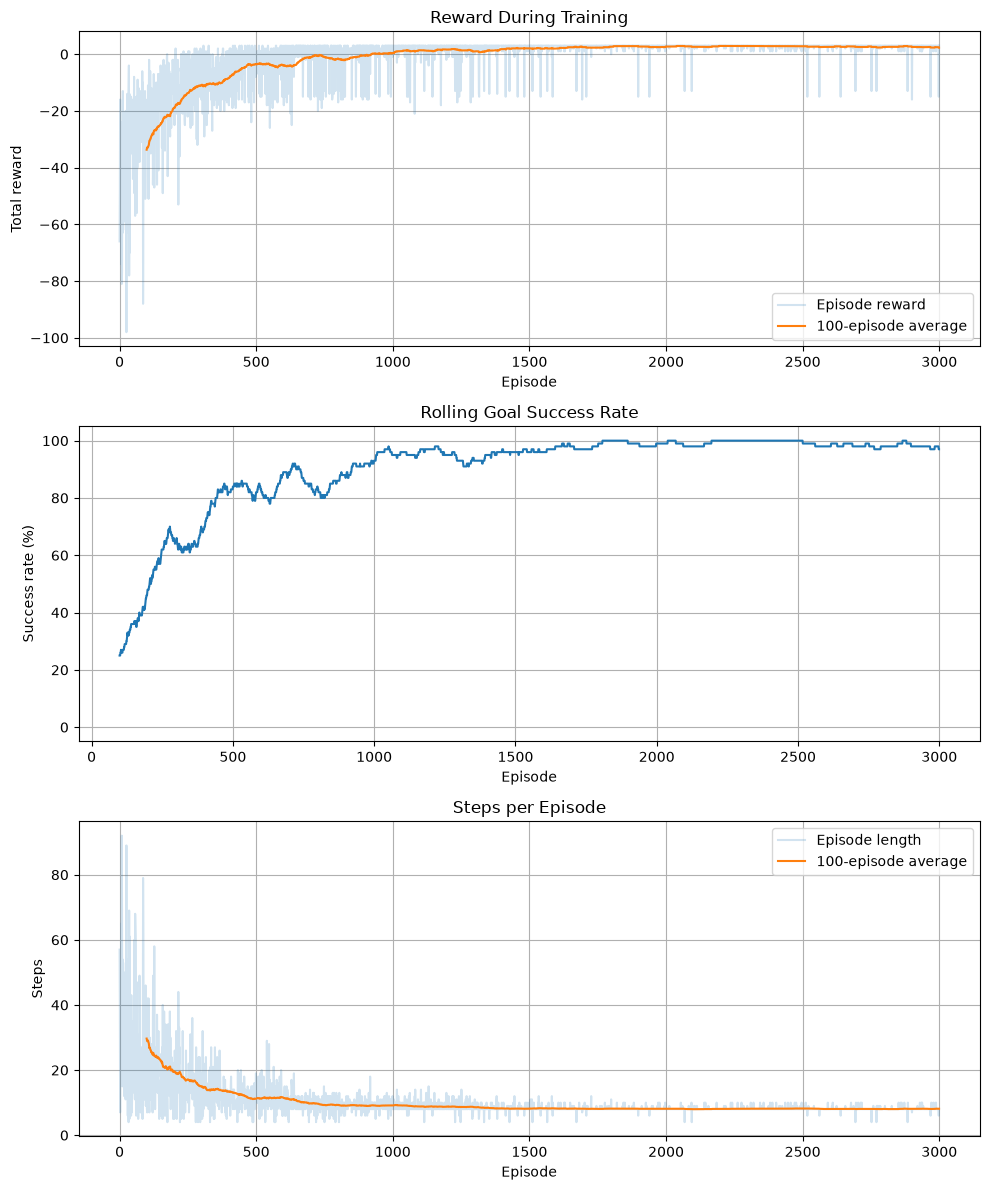

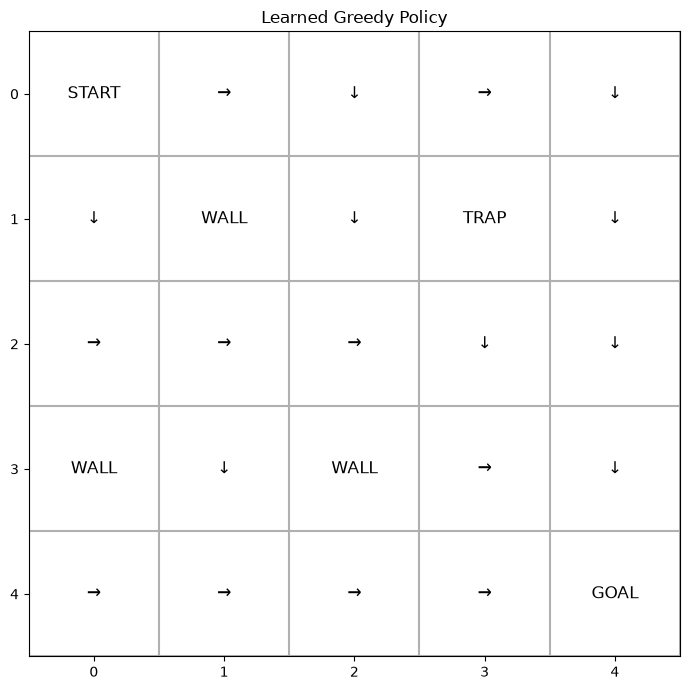


========== EVALUATION ==========
Episodes: 100
Goal reached: 100 (100.0%)
Trap reached: 0 (0.0%)
Timed out: 0 (0.0%)
Average reward: 3.00


In [5]:
# Training Loop ( With Visualization )

# -------------------------
# Configuration
# -------------------------

EPISODES = 3000
MAX_STEPS = 100

ALPHA = 0.1
GAMMA = 0.95

EPSILON_START = 1.0
EPSILON_MIN = 0.02
EPSILON_DECAY = 0.998

WINDOW = 100

ACTIONS = ["Up", "Down", "Left", "Right"]
ARROWS = ["↑", "↓", "←", "→"]


def choose_action(q_table, state, epsilon, rng):
    """Epsilon-greedy action selection."""

    if rng.random() < epsilon:
        return int(rng.integers(0, 4))

    values = q_table[state]
    best_actions = np.flatnonzero(
        np.isclose(values, values.max())
    )

    return int(rng.choice(best_actions))


def train():
    env = GridWorldEnv(max_steps=MAX_STEPS)
    rng = np.random.default_rng(42)

    q_table = np.zeros((25, 4))

    epsilon = EPSILON_START

    episode_rewards = []
    episode_successes = []
    episode_lengths = []

    for episode in range(EPISODES):
        state, info = env.reset()
        total_reward = 0
        success = 0

        for step in range(MAX_STEPS):
            action = choose_action(
                q_table, state, epsilon, rng
            )

            (
                next_state,
                reward,
                terminated,
                truncated,
                info,
            ) = env.step(action)

            # Q-learning update.
            old_value = q_table[state, action]

            if terminated:
                # Goal or trap: no future value.
                target = reward
            else:
                # Bootstrap on ordinary transitions and
                # time-limit truncations.
                target = reward + GAMMA * np.max(
                    q_table[next_state]
                )

            q_table[state, action] = old_value + ALPHA * (
                target - old_value
            )

            state = next_state
            total_reward += reward

            if terminated or truncated:
                if env.position == env.goal:
                    success = 1
                break

        episode_rewards.append(total_reward)
        episode_successes.append(success)
        episode_lengths.append(step + 1)

        epsilon = max(
            EPSILON_MIN,
            epsilon * EPSILON_DECAY,
        )

        if (episode + 1) % 300 == 0:
            avg_reward = np.mean(episode_rewards[-WINDOW:])
            success_rate = 100 * np.mean(
                episode_successes[-WINDOW:]
            )

            print(
                f"Episode {episode + 1:4d} | "
                f"Avg reward: {avg_reward:7.2f} | "
                f"Success rate: {success_rate:5.1f}% | "
                f"Epsilon: {epsilon:.3f}"
            )

    env.close()

    history = {
        "rewards": episode_rewards,
        "successes": episode_successes,
        "lengths": episode_lengths,
    }

    return q_table, history


def moving_average(values, window=WINDOW):
    """Smooth noisy episode metrics."""

    values = np.asarray(values, dtype=float)

    if len(values) < window:
        return values

    return np.convolve(
        values,
        np.ones(window) / window,
        mode="valid",
    )


def plot_training(history):
    """Plot rewards, success rate, and episode length."""

    rewards = history["rewards"]
    successes = history["successes"]
    lengths = history["lengths"]

    fig, axes = plt.subplots(3, 1, figsize=(10, 12))

    # 1. Episode rewards
    axes[0].plot(
        rewards,
        alpha=0.2,
        label="Episode reward",
    )

    axes[0].plot(
        np.arange(WINDOW - 1, len(rewards)),
        moving_average(rewards),
        label=f"{WINDOW}-episode average",
    )

    axes[0].set_title("Reward During Training")
    axes[0].set_xlabel("Episode")
    axes[0].set_ylabel("Total reward")
    axes[0].legend()
    axes[0].grid(True)

    # 2. Success rate
    success_curve = moving_average(successes) * 100

    axes[1].plot(
        np.arange(WINDOW - 1, len(successes)),
        success_curve,
    )

    axes[1].set_title("Rolling Goal Success Rate")
    axes[1].set_xlabel("Episode")
    axes[1].set_ylabel("Success rate (%)")
    axes[1].set_ylim(-5, 105)
    axes[1].grid(True)

    # 3. Episode length
    axes[2].plot(
        lengths,
        alpha=0.2,
        label="Episode length",
    )

    axes[2].plot(
        np.arange(WINDOW - 1, len(lengths)),
        moving_average(lengths),
        label=f"{WINDOW}-episode average",
    )

    axes[2].set_title("Steps per Episode")
    axes[2].set_xlabel("Episode")
    axes[2].set_ylabel("Steps")
    axes[2].legend()
    axes[2].grid(True)

    plt.tight_layout()
    plt.savefig("training_metrics.png", dpi=150)
    plt.show()


def show_policy(q_table):
    """Display the greedy action for each grid cell."""

    env = GridWorldEnv()
    policy = np.zeros((env.size, env.size))

    fig, ax = plt.subplots(figsize=(7, 7))

    # Draw the grid.
    ax.set_xlim(-0.5, env.size - 0.5)
    ax.set_ylim(env.size - 0.5, -0.5)
    ax.set_xticks(range(env.size))
    ax.set_yticks(range(env.size))
    ax.set_xticks(np.arange(-0.5, env.size, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, env.size, 1), minor=True)
    ax.grid(which="minor", linewidth=1.5)
    ax.tick_params(which="minor", bottom=False, left=False)

    for row in range(env.size):
        for col in range(env.size):
            pos = (row, col)
            state = row * env.size + col

            if pos == env.start:
                label = "START"
            elif pos == env.goal:
                label = "GOAL"
            elif pos == env.trap:
                label = "TRAP"
            elif pos in env.walls:
                label = "WALL"
            else:
                best_action = int(np.argmax(q_table[state]))
                label = ARROWS[best_action]
                policy[row, col] = best_action

            ax.text(
                col,
                row,
                label,
                ha="center",
                va="center",
                fontsize=12,
            )

    ax.set_title("Learned Greedy Policy")
    plt.tight_layout()
    plt.savefig("learned_policy.png", dpi=150)
    plt.show()

    env.close()


def evaluate(q_table, episodes=100):
    """Evaluate the greedy policy without exploration."""

    env = GridWorldEnv(max_steps=MAX_STEPS)
    rng = np.random.default_rng(123)

    successes = 0
    traps = 0
    timeouts = 0
    total_rewards = []

    for _ in range(episodes):
        state, info = env.reset()
        total_reward = 0

        for step in range(MAX_STEPS):
            values = q_table[state]
            best_actions = np.flatnonzero(
                np.isclose(values, values.max())
            )
            action = int(rng.choice(best_actions))

            (
                state,
                reward,
                terminated,
                truncated,
                info,
            ) = env.step(action)

            total_reward += reward

            if terminated or truncated:
                break

        if env.position == env.goal:
            successes += 1
        elif env.position == env.trap:
            traps += 1
        else:
            timeouts += 1

        total_rewards.append(total_reward)
        

    env.close()

    print("\n========== EVALUATION ==========")
    print(f"Episodes: {episodes}")
    print(f"Goal reached: {successes} ({successes / episodes:.1%})")
    print(f"Trap reached: {traps} ({traps / episodes:.1%})")
    print(f"Timed out: {timeouts} ({timeouts / episodes:.1%})")
    print(f"Average reward: {np.mean(total_rewards):.2f}")



q_table, history = train()

print("\nLearned Q-table:")
print(np.round(q_table, 2))

plot_training(history)
show_policy(q_table)
evaluate(q_table)
